In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B13 – Phát Hiện Mã Độc Bằng Naive Bayes
## Đặc Trưng Tĩnh PE Header – Dataset Malware-Benign

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PowerTransformer,
                                   StandardScaler)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
_name = "Malware-Benign.csv"
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR.parent / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR / "Dataset" / "malware-benignpe-files" / _name,
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "Malware"               # 0 = file lành tính, 1 = mã độc
TARGET_NAMES = ["Benign", "Malware"]
ID_COL = "Hash_md5_Name"            # cột định danh, bỏ trước khi lọc trùng
META_COLS = []

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ
# ==========================
# var_smoothing: lượng cộng thêm vào phương sai của GaussianNB, tính theo
# tỷ lệ với phương sai lớn nhất trong các đặc trưng. Mặc định của sklearn
# là 1e-9 — bài này sẽ cho thấy giá trị mặc định đó thường quá nhỏ.
VS_GRID = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]

# Ngưỡng tương quan để coi hai đặc trưng là "trùng lặp thông tin"
CORR_THR = 0.95

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
VARIANTS_COMMENT = (
    "\nNhận xét: GaussianNB với tham số mặc định gần như vô dụng (F1 ≈ 0,13 trên\n"
    "dữ liệu thô và ≈ 0,26 sau chuẩn hóa), trong khi BernoulliNB đạt ≈ 0,92 và\n"
    "MultinomialNB ≈ 0,83. Nghịch lý: BernoulliNB chỉ dùng thông tin \"đặc trưng\n"
    "này lớn hơn một nửa khoảng giá trị hay không\" mà vẫn thắng áp đảo mô hình\n"
    "dùng toàn bộ giá trị số. Điều đó gợi ý giả định phân phối chuẩn của\n"
    "GaussianNB bị vi phạm rất nặng trên đặc trưng PE header → xem A3 và A4.")
VS_COMMENT = (
    "\nNhận xét: khác với bộ dữ liệu của CV4.1, ở đây var_smoothing gần như\n"
    "KHÔNG cứu được GaussianNB — giá trị tốt nhất chỉ đưa F1 từ 0,26 lên 0,28.\n"
    "Kết luận: nguyên nhân chính không phải phương sai nhỏ mà là hình dạng phân\n"
    "phối. Phần A4 xử lý đúng nguyên nhân đó.")
SKEW_COMMENT = (
    "\nNhận xét: 61 trong 69 đặc trưng có |độ lệch| > 2, trung vị độ lệch tới\n"
    "23,49 — đặc trưng PE header lệch nặng hơn cả dữ liệu lưu lượng mạng. Điều\n"
    "này hợp lý: các trường như SizeOfImage hay ImageBase phần lớn mẫu nằm ở\n"
    "vài giá trị phổ biến còn một số ít mẫu rất lớn.\n"
    "PowerTransformer kéo trung vị độ lệch xuống 0,52 và F1 từ 0,28 lên 0,92 —\n"
    "gấp hơn ba lần. Đây là minh chứng mạnh nhất trong cả ba bài về việc biến\n"
    "đổi dữ liệu cho khớp giả định quan trọng hơn dò siêu tham số.")
CORR_COMMENT = (
    "\nNhận xét: chỉ 5 trong 2.346 cặp có |r| > 0,95 nhưng vẫn tồn tại cặp\n"
    "tương quan 1,0 — các trường PE header trùng lặp thông tin (ví dụ nhóm\n"
    "SizeOf* và các trường section tương ứng). Loại 5 đặc trưng còn 64 giúp F1\n"
    "nhích lên, phù hợp với lý thuyết: bớt đặc trưng trùng lặp thì mô hình bớt\n"
    "đếm bằng chứng hai lần.")
CALIB_COMMENT = (
    "\nNhận xét: khoảng 65% mẫu bị gán xác suất cực đoan, và hiệu chỉnh isotonic\n"
    "kéo Brier từ 0,094 xuống 0,051 — gần một nửa. Với sản phẩm diệt virus,\n"
    "xác suất đáng tin là điều kiện để đặt ngưỡng chặn sao cho tỷ lệ báo động\n"
    "giả nằm dưới một mức cho trước; mô hình chưa hiệu chỉnh không cho phép làm\n"
    "điều đó.")
FINAL_COMMENT = (
    "\nNhận xét: hạ ngưỡng từ 0,50 xuống 0,05 đưa F1 từ 0,927 lên 0,949 — ở đây\n"
    "tinh chỉnh ngưỡng có tác dụng rõ, khác với bộ dữ liệu của CV4.1. Random\n"
    "Forest vẫn vượt xa (F1 0,994, AUC 0,998). Ưu thế duy nhất của Naive Bayes\n"
    "là thời gian huấn luyện — nhanh hơn hàng chục lần — nên nó phù hợp làm\n"
    "baseline để biết một bộ dữ liệu mới có \"dễ\" hay không trước khi đầu tư\n"
    "vào mô hình phức tạp.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn nhỏ → kết quả ổn định. Lưu ý con số này chỉ đáng\n"
    "tin vì ta đã lọc trùng ở A1; nếu còn dòng trùng lặp thì cross-validation\n"
    "cũng bị thổi phồng y như một lần chia đơn lẻ.")

print("✅ Cấu hình xong!")
print(f"   Nhãn      → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   VS_GRID   → {VS_GRID}")
print(f"   CORR_THR  → {CORR_THR}")
print(f"   Dataset   → {CSV_PATH}")


✅ Cấu hình xong!
   Nhãn      → Malware (0 = Benign, 1 = Malware)
   Test size → 30%  |  SEED = 42  |  CV folds = 5
   VS_GRID   → [1e-11, 1e-09, 1e-07, 1e-05, 0.001, 0.01, 0.1, 1.0]
   CORR_THR  → 0.95
   Dataset   → C:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.2\CV4.2\Dataset\Dataset\malware-benignpe-files\Malware-Benign.csv


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA biến đổi:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# BỘ LỌC ĐẶC TRƯNG TƯƠNG QUAN CAO
# ════════════════════════════════════════════════════════════════════════════
# Naive Bayes giả định các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Hai
# đặc trưng tương quan gần như hoàn hảo sẽ bị mô hình đếm bằng chứng HAI LẦN,
# khiến xác suất bị đẩy về 0 hoặc 1. Bộ lọc này giữ lại một đặc trưng trong
# mỗi cặp có |tương quan| vượt ngưỡng.
#
# Viết dưới dạng transformer của scikit-learn để có thể đặt vào Pipeline —
# nhờ đó khi chạy cross-validation ở phần A8, bộ lọc được fit lại trên từng
# fold thay vì dùng kết quả tính trên toàn bộ dữ liệu (tránh rò rỉ).
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        C = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        upper = np.triu(C, k=1)                      # chỉ xét tam giác trên
        drop = {int(j) for _, j in zip(*np.where(upper > self.threshold))}
        self.keep_ = [i for i in range(X.shape[1]) if i not in drop]
        self.n_dropped_ = X.shape[1] - len(self.keep_)
        self.n_pairs_ = int((upper > self.threshold).sum())
        self.max_corr_ = float(upper.max())
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_]


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Ngoài các chỉ số quen thuộc, bài này thêm Brier score — trung bình bình
# phương sai lệch giữa xác suất dự đoán và nhãn thật. Brier càng NHỎ càng tốt.
# Chỉ số này cần thiết vì Naive Bayes nổi tiếng cho xác suất rất lệch.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "brier": brier_score_loss(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()")


✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()


---
# Xây Dựng Mô Hình Naive Bayes

> **Bài toán:** Dự đoán một file thực thi là **Benign (0)** hay **Malware (1)** chỉ từ đặc trưng tĩnh của PE header.
>
> **Ý tưởng của Naive Bayes:** tính xác suất theo định lý Bayes với giả định các đặc trưng độc lập nhau khi đã biết lớp.
>
> **Điều bài này tập trung vào:** GaussianNB mặc định sẽ cho kết quả gần như vô dụng trên bộ dữ liệu này. Bài học nằm ở chỗ chẩn đoán đúng nguyên nhân và sửa nó.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU PE HEADER (Malware-Benign)")
print("═" * 70)

df = pd.read_csv(CSV_PATH)
print(f"Shape gốc : {df.shape}")

# ── Bỏ cột định danh TRƯỚC khi lọc trùng ────────────────────────────────────
# Thứ tự bắt buộc: nếu giữ cột hash thì mỗi dòng đều có giá trị định danh
# riêng, không dòng nào bị coi là trùng và drop_duplicates() vô hiệu.
n_before = len(df)
df = df.drop(columns=[ID_COL]).drop_duplicates().reset_index(drop=True)
print(f"Sau khi bỏ cột {ID_COL} và lọc trùng: {df.shape} "
      f"(loại {n_before - len(df):,} dòng trùng)")

y = df[LABEL_COL].astype(int).values
print(f"\nPhân phối nhãn:")
print(f"   {TARGET_NAMES[0]}(0) : {int((y == 0).sum()):,}")
print(f"   {TARGET_NAMES[1]}(1) : {int((y == 1).sum()):,}")
print(f"   Tỷ lệ mã độc  : {(y == 1).mean()*100:.2f}%")

X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0: {zero_var}")
print(f"   Số đặc trưng : {X_raw.shape[1]}")
print(f"   Số mẫu       : {X_raw.shape[0]:,}")

# ── Chia train/test TRƯỚC, biến đổi SAU ─────────────────────────────────────
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)           # cho GaussianNB
X_tr, X_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)

minmax = MinMaxScaler().fit(X_tr_raw)             # cho Bernoulli / Multinomial
X_tr_mm = minmax.transform(X_tr_raw)
X_te_mm = np.clip(minmax.transform(X_te_raw), 0, None)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} mã độc)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} mã độc)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU PE HEADER (Malware-Benign)
══════════════════════════════════════════════════════════════════════


Shape gốc : (19611, 79)


Sau khi bỏ cột Hash_md5_Name và lọc trùng: (16640, 78) (loại 2,971 dòng trùng)

Phân phối nhãn:
   Benign(0) : 4,966
   Malware(1) : 11,674
   Tỷ lệ mã độc  : 70.16%



✅ Sau tiền xử lý:
   Loại 8 cột phương sai = 0: ['e_magic', 'SectionMaxEntropy', 'SectionMaxRawsize', 'SectionMaxVirtualsize', 'SectionMinPhysical', 'SectionMinVirtual', 'SectionMinPointerData', 'SectionMainChar']
   Số đặc trưng : 69
   Số mẫu       : 16,640

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 11,648 mẫu (8,172 mã độc)
   Test  : 4,992 mẫu (3,502 mã độc)


### A2. Ba Biến Thể Naive Bayes: Gaussian, Bernoulli, Multinomial

                                       acc    prec     rec      f1     auc  \
model                                                                        
GaussianNB (dữ liệu thô)            0.3484  0.9844  0.0722  0.1346  0.7976   
GaussianNB (Z-score)                0.4006  0.9705  0.1502  0.2601  0.9260   
BernoulliNB (MinMax, binarize=0.5)  0.8922  0.9413  0.9026  0.9216  0.9460   
MultinomialNB (MinMax)              0.7402  0.7569  0.9275  0.8336  0.8921   

                                     brier  
model                                       
GaussianNB (dữ liệu thô)            0.6516  
GaussianNB (Z-score)                0.5991  
BernoulliNB (MinMax, binarize=0.5)  0.0732  
MultinomialNB (MinMax)              0.1682  

GaussianNB: thô F1 = 0.1346 | Z-score F1 = 0.2601  → chênh +0.1255

Nhận xét: GaussianNB với tham số mặc định gần như vô dụng (F1 ≈ 0,13 trên
dữ liệu thô và ≈ 0,26 sau chuẩn hóa), trong khi BernoulliNB đạt ≈ 0,92 và
MultinomialNB ≈ 0,83. Nghịch lý: BernoulliNB

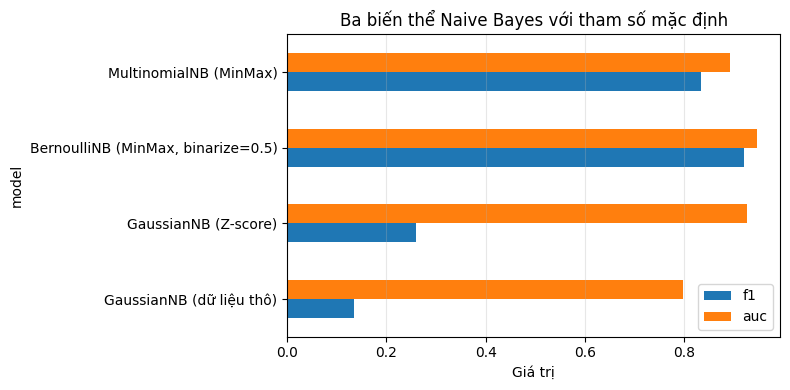

In [5]:
# Naive Bayes dựa trên định lý Bayes cùng một giả định đơn giản hóa mạnh:
# các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Nhờ đó xác suất hợp của
# nhiều đặc trưng trở thành phép nhân các xác suất lẻ, và mô hình chỉ cần
# đếm thống kê từng đặc trưng một lần — huấn luyện cực nhanh.
#
# Ba biến thể khác nhau ở chỗ mô hình hóa P(đặc trưng | lớp) như thế nào:
#   GaussianNB    – giả định mỗi đặc trưng theo phân phối chuẩn trong từng lớp
#   BernoulliNB   – giả định đặc trưng nhị phân (có / không), cần binarize
#   MultinomialNB – giả định đặc trưng là số đếm không âm, cần đưa về [0, 1]
rows = []

g_raw = GaussianNB().fit(X_tr_raw, y_tr)
rows.append(evaluate(y_te, g_raw.predict(X_te_raw),
                     g_raw.predict_proba(X_te_raw)[:, 1], "GaussianNB (dữ liệu thô)"))

g_std = GaussianNB().fit(X_tr, y_tr)
rows.append(evaluate(y_te, g_std.predict(X_te),
                     g_std.predict_proba(X_te)[:, 1], "GaussianNB (Z-score)"))

bnb = BernoulliNB(binarize=0.5).fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, bnb.predict(X_te_mm),
                     bnb.predict_proba(X_te_mm)[:, 1], "BernoulliNB (MinMax, binarize=0.5)"))

mnb = MultinomialNB().fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, mnb.predict(X_te_mm),
                     mnb.predict_proba(X_te_mm)[:, 1], "MultinomialNB (MinMax)"))

var_df = pd.DataFrame(rows).set_index("model").round(4)
print(var_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(f"\nGaussianNB: thô F1 = {rows[0]['f1']:.4f} | Z-score F1 = {rows[1]['f1']:.4f}"
      f"  → chênh {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(VARIANTS_COMMENT)

ax = var_df[["f1", "auc"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("Giá trị")
ax.set_title("Ba biến thể Naive Bayes với tham số mặc định")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. var_smoothing – Siêu Tham Số Quyết Định Của GaussianNB

                  acc    prec     rec      f1     auc
var_smoothing                                        
1.000000e-11   0.4008  0.9776  0.1493  0.2591  0.9262
1.000000e-09   0.4006  0.9705  0.1502  0.2601  0.9260
1.000000e-07   0.4008  0.9688  0.1508  0.2609  0.9259
1.000000e-05   0.3974  0.9901  0.1425  0.2491  0.9261
1.000000e-03   0.4046  0.9766  0.1551  0.2676  0.9265
1.000000e-02   0.4111  0.9779  0.1642  0.2812  0.9263
1.000000e-01   0.3872  0.9826  0.1288  0.2277  0.9310
1.000000e+00   0.3506  0.9851  0.0754  0.1401  0.9339

→ var_smoothing tốt nhất trên dữ liệu Z-score: 0.01  (F1 = 0.2812)
→ So với mặc định 1e-09 (F1 = 0.2601): +0.0211

Nhận xét: khác với bộ dữ liệu của CV4.1, ở đây var_smoothing gần như
KHÔNG cứu được GaussianNB — giá trị tốt nhất chỉ đưa F1 từ 0,26 lên 0,28.
Kết luận: nguyên nhân chính không phải phương sai nhỏ mà là hình dạng phân
phối. Phần A4 xử lý đúng nguyên nhân đó.


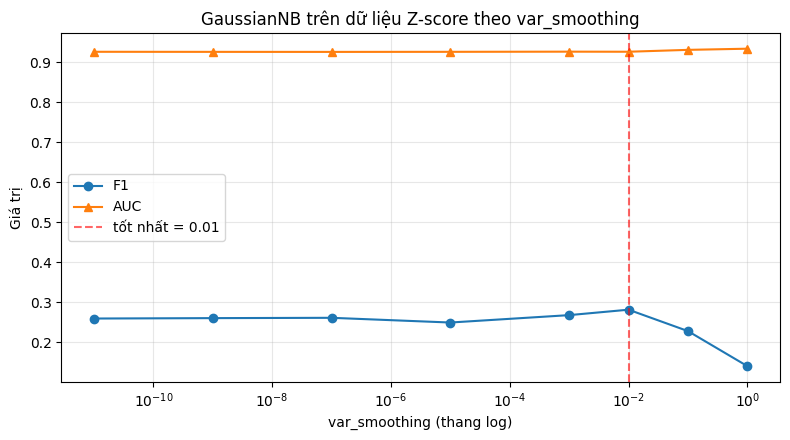

In [6]:
# Về lý thuyết, GaussianNB BẤT BIẾN với phép co giãn tuyến tính từng đặc
# trưng: nó chỉ ước lượng trung bình và phương sai của mỗi đặc trưng trong
# mỗi lớp. Nhưng kết quả ở A2 cho thấy chuẩn hóa lại làm thay đổi F1 rất
# mạnh. Nguyên nhân nằm ở var_smoothing.
#
# scikit-learn cộng thêm vào phương sai mỗi đặc trưng một lượng
#     var_smoothing × (phương sai LỚN NHẤT trong toàn bộ các đặc trưng)
# Trên dữ liệu thô, phương sai lớn nhất có thể tới hàng tỷ nên lượng cộng
# thêm rất đáng kể. Sau khi chuẩn hóa, mọi phương sai bằng 1 nên lượng cộng
# thêm chỉ còn 1e-9 — gần như bằng 0. Khi đó đặc trưng nào có phương sai
# trong lớp xấp xỉ 0 sẽ tạo ra mật độ Gauss cực nhọn, đẩy xác suất về 0 hoặc
# 1 và làm mô hình sụp đổ.
rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te), g.predict_proba(X_te)[:, 1], v))

vs_df = pd.DataFrame(rows).set_index("model").round(4)
vs_df.index.name = "var_smoothing"
print(vs_df[["acc", "prec", "rec", "f1", "auc"]])

vs_best = vs_df["f1"].idxmax()
print(f"\n→ var_smoothing tốt nhất trên dữ liệu Z-score: {vs_best:g}"
      f"  (F1 = {vs_df.loc[vs_best, 'f1']:.4f})")
print(f"→ So với mặc định 1e-09 (F1 = {vs_df.loc[1e-9, 'f1']:.4f}): "
      f"{vs_df.loc[vs_best, 'f1'] - vs_df.loc[1e-9, 'f1']:+.4f}")
print(VS_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(vs_df.index, vs_df["f1"], marker="o", label="F1")
ax.semilogx(vs_df.index, vs_df["auc"], marker="^", label="AUC")
ax.axvline(vs_best, color="red", ls="--", alpha=.6,
           label=f"tốt nhất = {vs_best:g}")
ax.set_xlabel("var_smoothing (thang log)")
ax.set_ylabel("Giá trị")
ax.set_title("GaussianNB trên dữ liệu Z-score theo var_smoothing")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. Kiểm Tra Giả Định Phân Phối Chuẩn

Độ lệch tuyệt đối của 69 đặc trưng (dữ liệu Z-score):
   trung vị      : 23.49
   lớn nhất      : 107.8
   số đặc trưng có |độ lệch| > 2  : 61
   số đặc trưng có |độ lệch| > 10 : 50



Sau PowerTransformer:
   trung vị      : 0.52
   số đặc trưng có |độ lệch| > 2  : 22



GaussianNB trên dữ liệu PowerTransformer:
                   f1     auc   brier
var_smoothing                        
1.000000e-11   0.2972  0.9533  0.5836
1.000000e-09   0.3333  0.9530  0.5631
1.000000e-07   0.4067  0.9530  0.5226
1.000000e-05   0.5798  0.9532  0.4067
1.000000e-03   0.6710  0.9538  0.3479
1.000000e-02   0.7110  0.9542  0.3158
1.000000e-01   0.7705  0.9549  0.2434
1.000000e+00   0.9173  0.9588  0.0940

→ Z-score            : F1 = 0.2812 (var_smoothing = 0.01)
→ PowerTransformer   : F1 = 0.9173 (var_smoothing = 1)
→ Biểu diễn dùng cho các phần sau: PowerTransformer với var_smoothing = 1

Nhận xét: 61 trong 69 đặc trưng có |độ lệch| > 2, trung vị độ lệch tới
23,49 — đặc trưng PE header lệch nặng hơn cả dữ liệu lưu lượng mạng. Điều
này hợp lý: các trường như SizeOfImage hay ImageBase phần lớn mẫu nằm ở
vài giá trị phổ biến còn một số ít mẫu rất lớn.
PowerTransformer kéo trung vị độ lệch xuống 0,52 và F1 từ 0,28 lên 0,92 —
gấp hơn ba lần. Đây là minh chứng mạnh nhất trong

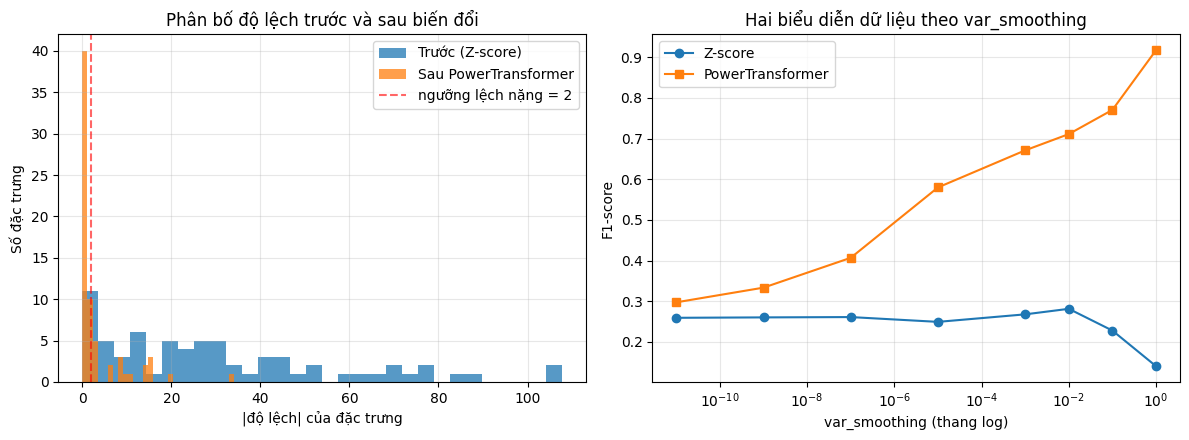

In [7]:
# GaussianNB giả định mỗi đặc trưng theo phân phối CHUẨN trong từng lớp.
# Ta kiểm tra giả định đó bằng độ lệch (skewness): phân phối chuẩn có độ
# lệch 0, |độ lệch| > 2 là lệch nặng.
#
# Độ lệch bất biến với phép co giãn tuyến tính, nên tính trên dữ liệu đã
# chuẩn hóa cho kết quả giống hệt dữ liệu thô nhưng không bị tràn số học.
skew_before = pd.DataFrame(X_tr).skew().abs()
print(f"Độ lệch tuyệt đối của {X_tr.shape[1]} đặc trưng (dữ liệu Z-score):")
print(f"   trung vị      : {skew_before.median():.2f}")
print(f"   lớn nhất      : {skew_before.max():.1f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_before > 2).sum())}")
print(f"   số đặc trưng có |độ lệch| > 10 : {int((skew_before > 10).sum())}")

# PowerTransformer (Yeo-Johnson) tìm một phép biến đổi lũy thừa cho từng đặc
# trưng sao cho kết quả gần phân phối chuẩn nhất, rồi chuẩn hóa về N(0, 1).
# Khác với log, Yeo-Johnson xử lý được cả giá trị âm và giá trị 0.
pt = PowerTransformer(method="yeo-johnson", standardize=True).fit(X_tr_raw)
X_tr_pt, X_te_pt = pt.transform(X_tr_raw), pt.transform(X_te_raw)

skew_after = pd.DataFrame(X_tr_pt).skew().abs()
print(f"\nSau PowerTransformer:")
print(f"   trung vị      : {skew_after.median():.2f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_after > 2).sum())}")

rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr_pt, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te_pt),
                         g.predict_proba(X_te_pt)[:, 1], v))
pt_df = pd.DataFrame(rows).set_index("model").round(4)
pt_df.index.name = "var_smoothing"
print(f"\nGaussianNB trên dữ liệu PowerTransformer:")
print(pt_df[["f1", "auc", "brier"]])

vs_best_pt = pt_df["f1"].idxmax()
f1_std, f1_pt = vs_df.loc[vs_best, "f1"], pt_df.loc[vs_best_pt, "f1"]
print(f"\n→ Z-score            : F1 = {f1_std:.4f} (var_smoothing = {vs_best:g})")
print(f"→ PowerTransformer   : F1 = {f1_pt:.4f} (var_smoothing = {vs_best_pt:g})")

# Chọn biểu diễn tốt hơn làm biểu diễn cuối cho các phần sau
if f1_pt >= f1_std:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "PowerTransformer", X_tr_pt, X_te_pt, vs_best_pt, pt
else:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "Z-score", X_tr, X_te, vs_best, scaler
print(f"→ Biểu diễn dùng cho các phần sau: {REPR} "
      f"với var_smoothing = {VS_F:g}")
print(SKEW_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew_before, bins=30, alpha=.75, label="Trước (Z-score)")
axes[0].hist(skew_after, bins=30, alpha=.75, label="Sau PowerTransformer")
axes[0].axvline(2, color="red", ls="--", alpha=.6, label="ngưỡng lệch nặng = 2")
axes[0].set_xlabel("|độ lệch| của đặc trưng")
axes[0].set_ylabel("Số đặc trưng")
axes[0].set_title("Phân bố độ lệch trước và sau biến đổi")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].semilogx(vs_df.index, vs_df["f1"], marker="o", label="Z-score")
axes[1].semilogx(pt_df.index, pt_df["f1"], marker="s", label="PowerTransformer")
axes[1].set_xlabel("var_smoothing (thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Hai biểu diễn dữ liệu theo var_smoothing")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A5. Kiểm Tra Giả Định Độc Lập Điều Kiện

Số cặp đặc trưng : 2,346
Số cặp có |r| > 0.95 : 5
Tương quan lớn nhất giữa hai đặc trưng khác nhau: 1.0000

Loại 5 đặc trưng, còn lại 64

                                      acc    prec     rec      f1     auc  \
model                                                                       
Toàn bộ 69 đặc trưng               0.8904  0.9749  0.8661  0.9173  0.9588   
Sau lọc tương quan (64 đặc trưng)  0.9026  0.9739  0.8849  0.9273  0.9633   

                                    brier  
model                                      
Toàn bộ 69 đặc trưng               0.0940  
Sau lọc tương quan (64 đặc trưng)  0.0852  

Nhận xét: chỉ 5 trong 2.346 cặp có |r| > 0,95 nhưng vẫn tồn tại cặp
tương quan 1,0 — các trường PE header trùng lặp thông tin (ví dụ nhóm
SizeOf* và các trường section tương ứng). Loại 5 đặc trưng còn 64 giúp F1
nhích lên, phù hợp với lý thuyết: bớt đặc trưng trùng lặp thì mô hình bớt
đếm bằng chứng hai lần.


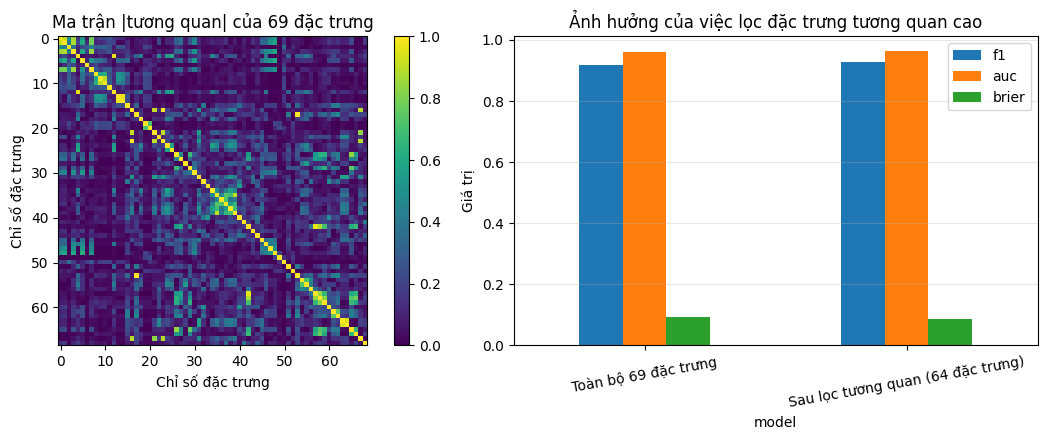

In [8]:
# Giả định "độc lập điều kiện" là chỗ chữ NAIVE trong tên thuật toán. Dữ
# liệu thật hầu như luôn vi phạm nó. Ta đo mức vi phạm bằng cách đếm số cặp
# đặc trưng có |tương quan| vượt ngưỡng, rồi thử loại bớt và đo lại.
cf = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
n_pairs_total = X_tr_f.shape[1] * (X_tr_f.shape[1] - 1) // 2

print(f"Số cặp đặc trưng : {n_pairs_total:,}")
print(f"Số cặp có |r| > {CORR_THR} : {cf.n_pairs_}")
print(f"Tương quan lớn nhất giữa hai đặc trưng khác nhau: {cf.max_corr_:.4f}")
print(f"\nLoại {cf.n_dropped_} đặc trưng, còn lại {len(cf.keep_)}")

X_tr_cf, X_te_cf = cf.transform(X_tr_f), cf.transform(X_te_f)
g_full = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
g_cf = GaussianNB(var_smoothing=VS_F).fit(X_tr_cf, y_tr)

rows = [
    evaluate(y_te, g_full.predict(X_te_f), g_full.predict_proba(X_te_f)[:, 1],
             f"Toàn bộ {X_tr_f.shape[1]} đặc trưng"),
    evaluate(y_te, g_cf.predict(X_te_cf), g_cf.predict_proba(X_te_cf)[:, 1],
             f"Sau lọc tương quan ({len(cf.keep_)} đặc trưng)"),
]
corr_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(corr_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CORR_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
C = np.nan_to_num(np.abs(np.corrcoef(np.asarray(X_tr_f, dtype=float), rowvar=False)))
im = axes[0].imshow(C, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title(f"Ma trận |tương quan| của {X_tr_f.shape[1]} đặc trưng")
axes[0].set_xlabel("Chỉ số đặc trưng")
axes[0].set_ylabel("Chỉ số đặc trưng")
plt.colorbar(im, ax=axes[0], fraction=.046)

corr_df[["f1", "auc", "brier"]].plot.bar(ax=axes[1], rot=10)
axes[1].set_title("Ảnh hưởng của việc lọc đặc trưng tương quan cao")
axes[1].set_ylabel("Giá trị")
axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A6. Hiệu Chỉnh Xác Suất (Calibration) & Điểm Brier

Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: 64.88%
Brier score khi chưa hiệu chỉnh : 0.0940
Brier score sau hiệu chỉnh      : 0.0510

                         acc    prec     rec      f1     auc  brier
model                                                              
Chưa hiệu chỉnh       0.8904  0.9749  0.8661  0.9173  0.9588  0.094
Isotonic calibration  0.9347  0.9446  0.9634  0.9539  0.9615  0.051

Nhận xét: khoảng 65% mẫu bị gán xác suất cực đoan, và hiệu chỉnh isotonic
kéo Brier từ 0,094 xuống 0,051 — gần một nửa. Với sản phẩm diệt virus,
xác suất đáng tin là điều kiện để đặt ngưỡng chặn sao cho tỷ lệ báo động
giả nằm dưới một mức cho trước; mô hình chưa hiệu chỉnh không cho phép làm
điều đó.


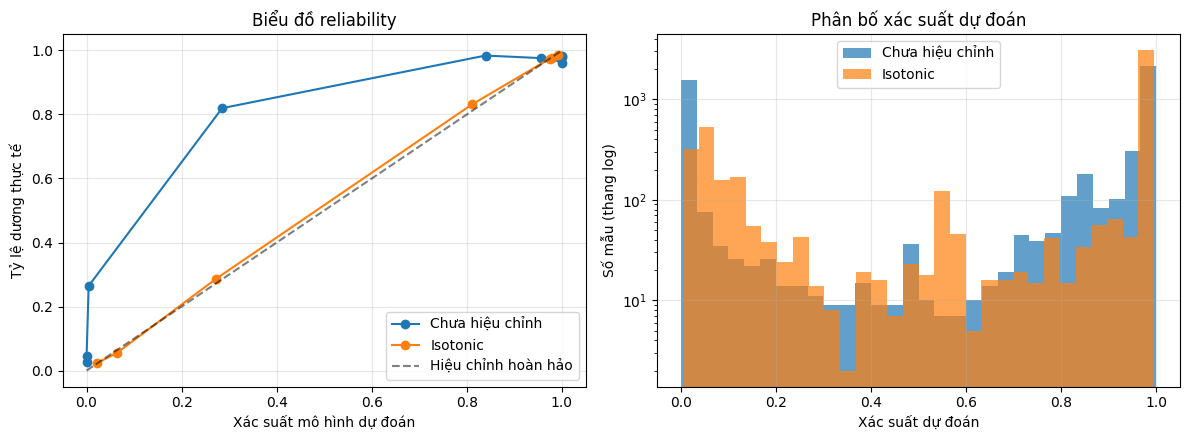

In [9]:
# Naive Bayes cho thứ hạng khá tốt (AUC cao) nhưng xác suất rất lệch: vì nhân
# dồn nhiều xác suất lẻ của các đặc trưng không thực sự độc lập, kết quả bị
# đẩy sát 0 hoặc 1. Mô hình "nói" 99% trong khi thực tế chỉ đúng 70%.
#
# Brier score đo trực tiếp sai lệch đó. Biểu đồ reliability vẽ tỷ lệ dương
# thực tế theo từng khoảng xác suất dự đoán — đường lý tưởng là đường chéo.
base = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
p_uncal = base.predict_proba(X_te_f)[:, 1]

frac_extreme = ((p_uncal < 0.01) | (p_uncal > 0.99)).mean()
print(f"Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: {frac_extreme:.2%}")
print(f"Brier score khi chưa hiệu chỉnh : {brier_score_loss(y_te, p_uncal):.4f}")

# CalibratedClassifierCV học lại một hàm đơn điệu ánh xạ điểm của mô hình
# sang xác suất thật, dùng cross-validation nội bộ trên tập train.
cal = CalibratedClassifierCV(GaussianNB(var_smoothing=VS_F),
                             method="isotonic", cv=5)
cal.fit(X_tr_f, y_tr)
p_cal = cal.predict_proba(X_te_f)[:, 1]
print(f"Brier score sau hiệu chỉnh      : {brier_score_loss(y_te, p_cal):.4f}")

rows = [
    evaluate(y_te, base.predict(X_te_f), p_uncal, "Chưa hiệu chỉnh"),
    evaluate(y_te, cal.predict(X_te_f), p_cal, "Isotonic calibration"),
]
cal_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(cal_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CALIB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nm, p in [("Chưa hiệu chỉnh", p_uncal), ("Isotonic", p_cal)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="Hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(p_uncal, bins=30, alpha=.7, label="Chưa hiệu chỉnh")
axes[1].hist(p_cal, bins=30, alpha=.7, label="Isotonic")
axes[1].set_yscale("log")
axes[1].set_xlabel("Xác suất dự đoán")
axes[1].set_ylabel("Số mẫu (thang log)")
axes[1].set_title("Phân bố xác suất dự đoán")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Chọn Tập Đặc Trưng, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 9,318 mẫu để fit | 2,330 mẫu validation

F1 trên tập validation:
   Toàn bộ đặc trưng     : 0.9178
   Lọc tương quan        : 0.9228
→ Dùng bộ lọc tương quan: True
→ Số đặc trưng của mô hình cuối: 64

→ Ngưỡng tốt nhất trên validation: 0.05 (F1 = 0.9419; tại ngưỡng 0.50 chỉ đạt 0.9228)



                                               acc    prec     rec      f1  \
model                                                                        
GaussianNB (ngưỡng mặc định 0.50)           0.9026  0.9739  0.8849  0.9273   
GaussianNB (PowerTransformer, ngưỡng 0.05)  0.9297  0.9592  0.9397  0.9494   
Random Forest (200 cây)                     0.9912  0.9895  0.9980  0.9937   

                                            f1_macro     auc   brier  
model                                                                 
GaussianNB (ngưỡng mặc định 0.50)             0.8900  0.9633  0.0852  
GaussianNB (PowerTransformer, ngưỡng 0.05)    0.9172  0.9633  0.0852  
Random Forest (200 cây)                       0.9894  0.9981  0.0081  

Thời gian huấn luyện: Naive Bayes 13.2 ms | Random Forest 791.3 ms  → nhanh hơn khoảng 60 lần

Confusion matrix Naive Bayes:  TN=1350  FP=140  FN=211  TP=3291
  FP = 140 cảnh báo giả | FN = 211 lần bỏ sót malware

              precision    recall  f1-

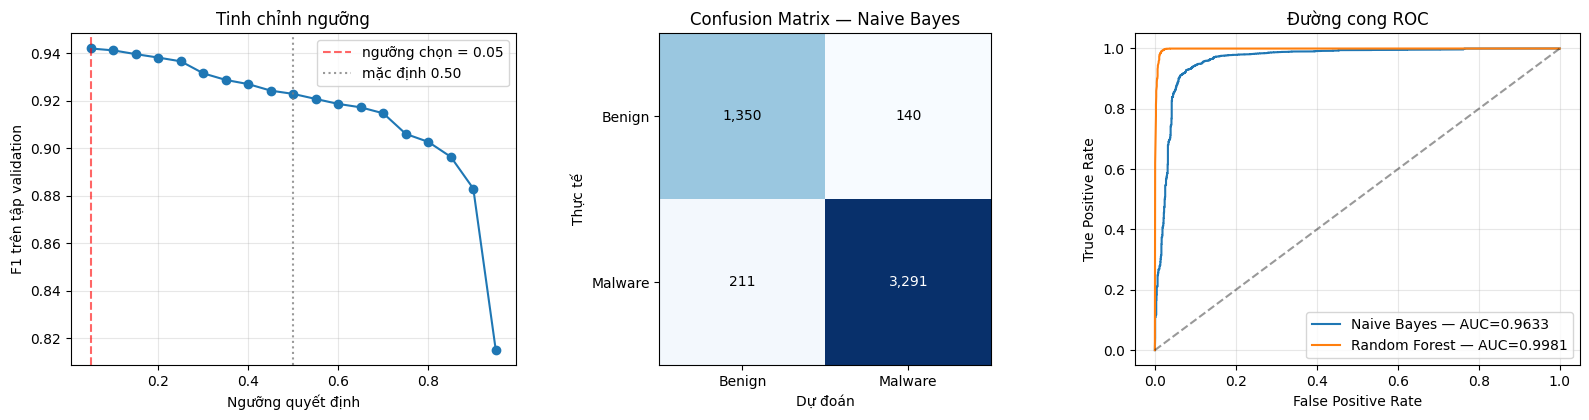

In [10]:
# Hai quyết định còn lại — dùng bộ lọc tương quan hay không, và chọn ngưỡng
# quyết định nào — phải được đưa ra trên dữ liệu MÔ HÌNH CHƯA THẤY, nhưng
# cũng KHÔNG ĐƯỢC dùng tập test. Nếu chọn theo điểm trên tập test thì tập
# test không còn là phép thử độc lập nữa.
# Vì vậy ta tách thêm một tập validation từ chính tập train.
X_a, X_v, y_a, y_v = train_test_split(X_tr_f, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

# ── Quyết định 1: có dùng bộ lọc tương quan hay không ───────────────────────
pick = {}
for tag, use in [("Toàn bộ đặc trưng", False), ("Lọc tương quan", True)]:
    if use:
        c = CorrelationFilter(threshold=CORR_THR).fit(X_a)
        A, V = c.transform(X_a), c.transform(X_v)
    else:
        A, V = X_a, X_v
    g = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
    pick[tag] = f1_score(y_v, g.predict(V), zero_division=0)

print("\nF1 trên tập validation:")
for k, v in pick.items():
    print(f"   {k:22s}: {v:.4f}")
USE_CF = pick["Lọc tương quan"] > pick["Toàn bộ đặc trưng"]
print(f"→ Dùng bộ lọc tương quan: {USE_CF}")

if USE_CF:
    c_val = CorrelationFilter(threshold=CORR_THR).fit(X_a)
    A, V = c_val.transform(X_a), c_val.transform(X_v)
    cf_final = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
    X_tr_sel, X_te_sel = cf_final.transform(X_tr_f), cf_final.transform(X_te_f)
else:
    A, V = X_a, X_v
    cf_final = None
    X_tr_sel, X_te_sel = X_tr_f, X_te_f
print(f"→ Số đặc trưng của mô hình cuối: {X_tr_sel.shape[1]}")

# ── Quyết định 2: ngưỡng quyết định ─────────────────────────────────────────
# Ngưỡng mặc định 0.5 chỉ hợp lý khi xác suất đã được hiệu chỉnh tốt và hai
# lớp cân bằng. Với Naive Bayes thì cả hai điều đó đều không đúng.
g_val = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
p_val = g_val.predict_proba(V)[:, 1]
THR_GRID = np.arange(0.05, 0.96, 0.05)
f1_by_thr = [f1_score(y_v, (p_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:.2f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng 0.50 chỉ đạt "
      f"{f1_score(y_v, (p_val >= 0.5).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
p_final = final.predict_proba(X_te_sel)[:, 1]
y_pred = (p_final >= THR).astype(int)

nb_res = evaluate(y_te, y_pred, p_final,
                  f"GaussianNB ({REPR}, ngưỡng {THR:.2f})")
nb_res_05 = evaluate(y_te, (p_final >= 0.5).astype(int), p_final,
                     "GaussianNB (ngưỡng mặc định 0.50)")

# ── So sánh với Random Forest, kèm thời gian huấn luyện ────────────────────
t0 = time.perf_counter()
GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
t_nb = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr_sel, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te_sel)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te_sel), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([nb_res_05, nb_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "brier"]])
print(f"\nThời gian huấn luyện: Naive Bayes {t_nb*1000:.1f} ms | "
      f"Random Forest {t_rf*1000:.1f} ms  → nhanh hơn khoảng "
      f"{t_rf/max(t_nb, 1e-9):.0f} lần")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix Naive Bayes:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o")
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:.2f}")
axes[0].axvline(0.5, color="gray", ls=":", alpha=.8, label="mặc định 0.50")
axes[0].set_xlabel("Ngưỡng quyết định")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — Naive Bayes")

for nm, sc in [("Naive Bayes", p_final), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

Pipeline: vt → tf → cf → nb



F1 từng fold : [0.9288 0.9321 0.9273 0.9181 0.9302]
F1 trung bình: 0.9273 ± 0.0049
F1 của một lần chia train/test ở A7: 0.9494

Nhận xét: độ lệch chuẩn nhỏ → kết quả ổn định. Lưu ý con số này chỉ đáng
tin vì ta đã lọc trùng ở A1; nếu còn dòng trùng lặp thì cross-validation
cũng bị thổi phồng y như một lần chia đơn lẻ.


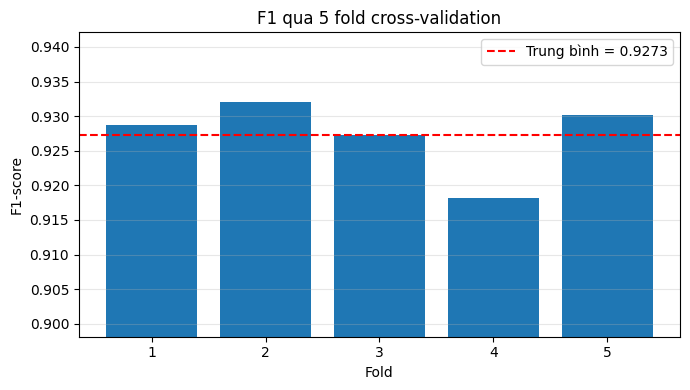

In [11]:
# Toàn bộ chuỗi biến đổi phải nằm TRONG Pipeline để mỗi fold tự fit lại trên
# phần train của riêng nó. Nếu biến đổi trước rồi mới chia fold thì thông tin
# của fold validation đã rò rỉ vào phép biến đổi.
#
# VarianceThreshold đứng đầu pipeline vì trong một fold có thể có đặc trưng
# trở thành hằng số; khi đó Yeo-Johnson không tìm được tham số lambda và báo
# lỗi BracketError.
steps = [("vt", VarianceThreshold())]
steps.append(("tf", PowerTransformer(standardize=True) if REPR == "PowerTransformer"
              else StandardScaler()))
if USE_CF:
    steps.append(("cf", CorrelationFilter(threshold=CORR_THR)))
steps.append(("nb", GaussianNB(var_smoothing=VS_F)))
pipe = Pipeline(steps)
print("Pipeline:", " → ".join(n for n, _ in steps))

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: {nb_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.02, max(scores) + 0.01)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. `GaussianNB` với tham số mặc định gần như vô dụng trên đặc trưng PE header: F1 chỉ 0,13 trên dữ liệu thô và 0,26 sau chuẩn hóa.
2. Dò `var_smoothing` hầu như không cứu được (0,26 → 0,28) — khác hẳn bộ dữ liệu của CV4.1.
3. Nguyên nhân thật là hình dạng phân phối: 61/69 đặc trưng có |độ lệch| > 2, trung vị độ lệch tới 23,49. `PowerTransformer` đưa F1 từ 0,28 lên 0,92.
4. `BernoulliNB` mặc định đạt 0,92 — bằng cả `GaussianNB` sau khi đã biến đổi, dù chỉ dùng thông tin nhị phân "lớn hơn một nửa khoảng giá trị hay không".
5. Hiệu chỉnh isotonic giảm Brier từ 0,094 xuống 0,051. Hạ ngưỡng từ 0,50 xuống 0,05 đưa F1 lên 0,949.
6. Random Forest vượt xa (F1 0,994, AUC 0,998); ưu thế của Naive Bayes chỉ còn là thời gian huấn luyện.

**Câu hỏi thảo luận**

1. Ở CV4.1 việc dò `var_smoothing` cải thiện hơn 0,2 F1, còn ở đây gần như không có tác dụng. Hãy giải thích sự khác biệt dựa trên bản chất của hai bộ đặc trưng.
2. `BernoulliNB` chỉ dùng thông tin nhị phân mà đạt 0,92, ngang với `GaussianNB` đã qua `PowerTransformer`. Điều này nói gì về cách thông tin phân biệt mã độc được mã hóa trong PE header?
3. Các trường như `SizeOfImage`, `ImageBase`, `CheckSum` có độ lệch rất lớn. Hãy giải thích vì sao đặc trưng PE header lại lệch nặng như vậy, dựa trên cách trình biên dịch sinh ra các giá trị này.
4. Vì sao phải bỏ cột hash **trước** khi gọi `drop_duplicates()`? Và vì sao dòng trùng lặp lại làm kết quả cross-validation ở phần A8 bị thổi phồng chứ không chỉ riêng một lần chia?
5. Với một sản phẩm diệt virus, xác suất đã hiệu chỉnh quan trọng ở chỗ nào? Hãy mô tả cụ thể cách dùng xác suất hiệu chỉnh để đặt ngưỡng sao cho tỷ lệ báo động giả không vượt một mức cho trước.
6. Ngưỡng tối ưu ở đây là 0,05 — rất thấp. Điều đó phản ánh mô hình đang thiên về phía nào, và vì sao?
7. Naive Bayes huấn luyện nhanh hơn Random Forest hàng chục lần. Hãy nêu một quy trình làm việc thực tế trong đó ưu thế đó có giá trị, dù Naive Bayes kém hơn về độ chính xác.
